# 07 - الكاميرا المباشرة: التقاط الصور وتسجيل الفيديو والمعالجة الحية

**المشروع:** Vision Studio - معالجة الصور والرؤية بالحاسوب  
**المقرر:** معالجة الصور والرؤية بالحاسوب - بكالوريوس ذكاء اصطناعي  
**إشراف:** الدكتورة سمية الشيبة

يستخدم هذا الدفتر كاميرا المتصفح في Google Colab لالتقاط الصور، وتسجيل فيديو قصير، ومعالجة إطارات الكاميرا مباشرة ثم حفظ النتائج.

## أهداف الدفتر

1. الوصول إلى كاميرا الجهاز من متصفح Colab بعد إذن المستخدم.
2. التقاط صورة وحفظها في مجلد صور الإدخال.
3. تسجيل فيديو قصير بالكاميرا وحفظه في مجلد فيديوهات الإدخال.
4. تطبيق الفلاتر على إطارات الكاميرا مباشرة.
5. عرض الإطار الأصلي والمعالج أثناء التشغيل.
6. حفظ جلسة المعالجة المباشرة كفيديو MP4 وصورة نهائية.
7. قياس سرعة المعالجة الفعلية وعدد الإطارات في الثانية.

> تنبيه: كاميرا Colab تمر عبر المتصفح والإنترنت، ولذلك لن تكون بسرعة تطبيق Android. التطبيق النهائي سيستخدم CameraX ويعمل دون إنترنت بالكامل.

## كيف تعمل كاميرا Colab؟

لا يعمل `cv2.VideoCapture(0)` في Colab؛ لأن الكود ينفذ على جهاز بعيد وليس على حاسوبك. لذلك نستخدم:

```text
كاميرا الجهاز → JavaScript في المتصفح → Python/OpenCV في Colab
```

أما في تطبيق Android فسيكون المسار محليًا وأسرع:

```text
CameraX → OpenCV Mat → المعالجة → العرض أو التسجيل
```

## 1. استيراد المكتبات وربط Google Drive

In [17]:
from pathlib import Path
from base64 import b64decode, b64encode
from datetime import datetime
import json
import shutil
import subprocess
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    PROJECT_ROOT = Path(
        '/content/drive/MyDrive/'
        'VisionStudio_Android_ImageProcessing'
    )
except ImportError:
    IN_COLAB = False
    PROJECT_ROOT = Path('VisionStudio_Android_ImageProcessing')

IMAGE_INPUT_DIR = PROJECT_ROOT / '02_Data/Images/Input'
VIDEO_INPUT_DIR = PROJECT_ROOT / '02_Data/Videos/Input'
CAMERA_IMAGE_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Images/07_Live_Camera_Processing'
)
CAMERA_VIDEO_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Videos/07_Live_Camera_Processing'
)

for directory in [
    IMAGE_INPUT_DIR,
    VIDEO_INPUT_DIR,
    CAMERA_IMAGE_OUTPUT_DIR,
    CAMERA_VIDEO_OUTPUT_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print('Running in Colab:', IN_COLAB)
print('Image input:', IMAGE_INPUT_DIR)
print('Video input:', VIDEO_INPUT_DIR)
print('Camera image output:', CAMERA_IMAGE_OUTPUT_DIR)
print('Camera video output:', CAMERA_VIDEO_OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running in Colab: True
Image input: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input
Video input: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Videos/Input
Camera image output: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/07_Live_Camera_Processing
Camera video output: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Videos/07_Live_Camera_Processing


## 2. دوال العرض والتحويل بين JavaScript وOpenCV

In [18]:
def to_rgb(image):
    if image.ndim == 2:
        return image
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def show_comparison(results, columns=2, figure_width=13):
    items = list(results.items())
    rows = int(np.ceil(len(items) / columns))
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(figure_width, rows * 4.5),
        squeeze=False
    )

    for axis, (title, result) in zip(axes.ravel(), items):
        axis.imshow(
            to_rgb(result),
            cmap='gray' if result.ndim == 2 else None
        )
        axis.set_title(title)
        axis.axis('off')

    for axis in axes.ravel()[len(items):]:
        axis.axis('off')

    plt.tight_layout()
    plt.show()


def data_url_to_bgr(data_url):
    if not data_url or ',' not in data_url:
        raise ValueError('لم تصل بيانات صورة صالحة من الكاميرا.')
    binary = b64decode(data_url.split(',', 1)[1])
    image_array = np.frombuffer(binary, dtype=np.uint8)
    frame = cv2.imdecode(image_array, cv2.IMREAD_COLOR)
    if frame is None:
        raise ValueError('تعذر تحويل إطار الكاميرا إلى صورة OpenCV.')
    return frame


def bgr_to_data_url(frame, quality=70):
    quality = int(np.clip(quality, 20, 95))
    success, encoded = cv2.imencode(
        '.jpg', frame,
        [cv2.IMWRITE_JPEG_QUALITY, quality]
    )
    if not success:
        raise ValueError('تعذر ترميز الإطار المعالج.')
    payload = b64encode(encoded.tobytes()).decode('ascii')
    return 'data:image/jpeg;base64,' + payload


def even_dimensions(frame, maximum_width=None):
    resized = frame
    height, width = frame.shape[:2]
    if maximum_width is not None and int(maximum_width) > 0:
        maximum_width = int(maximum_width)
        if width > maximum_width:
            scale = maximum_width / width
            new_height = max(2, int(round(height * scale)))
            resized = cv2.resize(
                frame, (maximum_width, new_height),
                interpolation=cv2.INTER_AREA
            )

    resized_height, resized_width = resized.shape[:2]
    even_height = max(2, resized_height - resized_height % 2)
    even_width = max(2, resized_width - resized_width % 2)
    return resized[:even_height, :even_width]

## 3. خوارزميات معالجة إطار الكاميرا

In [19]:
CAMERA_PROCESSING_MODES = [
    'original',
    'grayscale',
    'gaussian_blur',
    'median_blur',
    'bilateral',
    'sharpen',
    'canny',
    'threshold',
    'hsv_isolation',
    'hough_lines'
]


def sharpen_frame(frame):
    kernel = np.array([
        [0, -1, 0],
        [-1, 5, -1],
        [0, -1, 0]
    ], dtype=np.float32)
    return cv2.filter2D(frame, -1, kernel)


def hough_lines_frame(frame):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blurred, 50, 150)
    lines = cv2.HoughLinesP(
        edges, 1, np.pi / 180,
        threshold=40, minLineLength=50, maxLineGap=12
    )
    result = frame.copy()
    if lines is not None:
        for x1, y1, x2, y2 in np.asarray(lines).reshape(-1, 4):
            cv2.line(
                result,
                (int(x1), int(y1)), (int(x2), int(y2)),
                (0, 0, 255), 3
            )
    return result


def process_camera_frame(
    frame,
    mode='canny',
    low_threshold=100,
    high_threshold=200,
    threshold_value=127,
    lower_hsv=(0, 70, 50),
    upper_hsv=(20, 255, 255)
):
    if mode not in CAMERA_PROCESSING_MODES:
        raise ValueError(f'وضع المعالجة غير معروف: {mode}')

    if mode == 'original':
        return frame.copy()
    if mode == 'grayscale':
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        return cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    if mode == 'gaussian_blur':
        return cv2.GaussianBlur(frame, (7, 7), 0)
    if mode == 'median_blur':
        return cv2.medianBlur(frame, 7)
    if mode == 'bilateral':
        return cv2.bilateralFilter(frame, 9, 75, 75)
    if mode == 'sharpen':
        return sharpen_frame(frame)
    if mode == 'canny':
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        gray = cv2.GaussianBlur(gray, (5, 5), 0)
        edges = cv2.Canny(
            gray,
            max(0, int(low_threshold)),
            max(int(low_threshold) + 1, int(high_threshold))
        )
        return cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)
    if mode == 'threshold':
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        _, binary = cv2.threshold(
            gray, int(np.clip(threshold_value, 0, 255)),
            255, cv2.THRESH_BINARY
        )
        return cv2.cvtColor(binary, cv2.COLOR_GRAY2BGR)
    if mode == 'hsv_isolation':
        hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
        mask = cv2.inRange(
            hsv,
            np.array(lower_hsv, dtype=np.uint8),
            np.array(upper_hsv, dtype=np.uint8)
        )
        return cv2.bitwise_and(frame, frame, mask=mask)
    return hough_lines_frame(frame)

## 4. اختبار محرك المعالجة قبل تشغيل الكاميرا

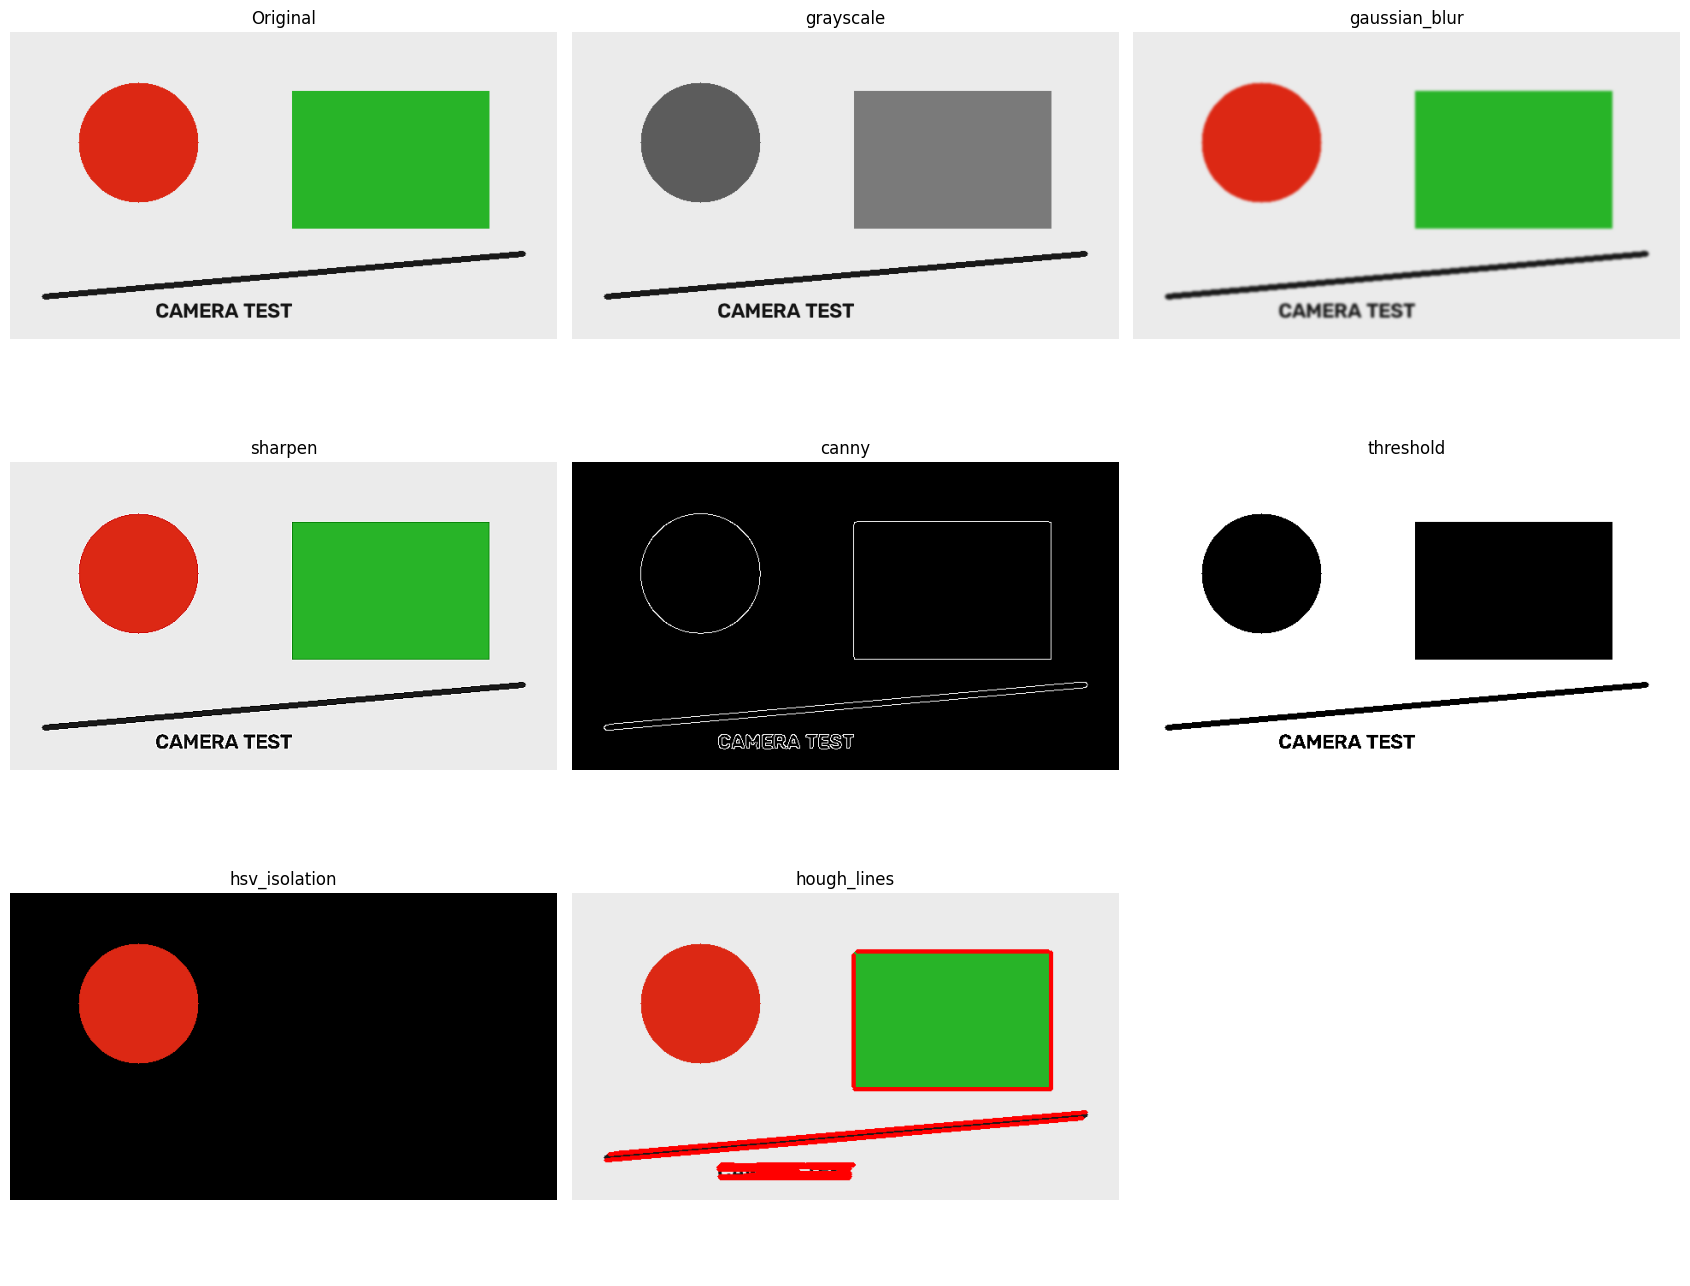

Camera processing engine test passed.
Saved: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/07_Live_Camera_Processing/camera_pipeline_test.png


In [20]:
test_frame = np.full((360, 640, 3), 235, dtype=np.uint8)
cv2.circle(test_frame, (150, 130), 70, (20, 40, 220), -1)
cv2.rectangle(test_frame, (330, 70), (560, 230), (40, 180, 40), -1)
cv2.line(test_frame, (40, 310), (600, 260), (25, 25, 25), 6)
cv2.putText(
    test_frame, 'CAMERA TEST', (170, 335),
    cv2.FONT_HERSHEY_SIMPLEX, 0.8,
    (20, 20, 20), 2, cv2.LINE_AA
)

test_results = {'Original': test_frame}
for mode in [
    'grayscale', 'gaussian_blur', 'sharpen',
    'canny', 'threshold', 'hsv_isolation', 'hough_lines'
]:
    test_results[mode] = process_camera_frame(test_frame, mode=mode)

show_comparison(test_results, columns=3, figure_width=17)

test_output_path = CAMERA_IMAGE_OUTPUT_DIR / 'camera_pipeline_test.png'
cv2.imwrite(
    str(test_output_path),
    process_camera_frame(test_frame, mode='canny')
)
print('Camera processing engine test passed.')
print('Saved:', test_output_path)

## 5. تجهيز اتصال الكاميرا في Colab

يستخدم الدفتر JavaScript مستقلًا داخل كل عملية كاميرا. بهذه الطريقة لا نعتمد على بقاء دوال JavaScript بين خلايا Colab، لأن بعض إصدارات Colab تعزل كل خلية في إطار منفصل.

هذه الخلية لا تشغل الكاميرا؛ بل تجهز دوال Python التي سترسل JavaScript وتنفذه في الاستدعاء نفسه.

In [21]:
CAMERA_JAVASCRIPT_READY = False

if IN_COLAB:
    from google.colab.output import eval_js
    CAMERA_JAVASCRIPT_READY = True
    print('Camera bridge is ready.')
else:
    print('وظائف الكاميرا تعمل داخل Google Colab فقط.')


def capture_photo_from_browser(width=640, quality=0.80):
    if not CAMERA_JAVASCRIPT_READY:
        raise RuntimeError('شغّل الدفتر داخل Google Colab لاستخدام الكاميرا.')

    script = r'''
    (async () => {
      const requestedWidth = __WIDTH__;
      const jpegQuality = __QUALITY__;
      const container = document.createElement('div');
      container.style.padding = '10px';
      container.style.border = '1px solid #bbb';

      const message = document.createElement('div');
      message.textContent = 'اضغط Capture Photo لالتقاط الصورة';
      const video = document.createElement('video');
      video.style.display = 'block';
      video.style.maxWidth = '100%';
      video.setAttribute('playsinline', '');
      video.muted = true;

      const button = document.createElement('button');
      button.textContent = 'Capture Photo';
      button.style.marginTop = '8px';

      container.appendChild(message);
      container.appendChild(video);
      container.appendChild(button);
      document.body.appendChild(container);

      let stream = null;
      try {
        stream = await navigator.mediaDevices.getUserMedia({
          video: {width: {ideal: requestedWidth}},
          audio: false
        });
        video.srcObject = stream;
        await video.play();
        google.colab.output.setIframeHeight(
          document.documentElement.scrollHeight, true
        );

        await new Promise(resolve => button.onclick = resolve);
        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);
        return canvas.toDataURL('image/jpeg', jpegQuality);
      } finally {
        if (stream) stream.getTracks().forEach(track => track.stop());
        container.remove();
      }
    })()
    '''
    script = script.replace('__WIDTH__', str(int(width)))
    script = script.replace('__QUALITY__', str(float(quality)))
    return eval_js(script, timeout_sec=120)


def record_video_from_browser(
    seconds=5, width=480, height=360, bitrate=250_000
):
    if not CAMERA_JAVASCRIPT_READY:
        raise RuntimeError('شغّل الدفتر داخل Google Colab لاستخدام الكاميرا.')

    script = r'''
    (async () => {
      const seconds = __SECONDS__;
      const width = __WIDTH__;
      const height = __HEIGHT__;
      const bitrate = __BITRATE__;
      let stream = null;
      let hasAudio = true;

      try {
        try {
          stream = await navigator.mediaDevices.getUserMedia({
            video: {
              width: {ideal: width}, height: {ideal: height},
              frameRate: {ideal: 15, max: 20}
            },
            audio: true
          });
        } catch (audioError) {
          hasAudio = false;
          stream = await navigator.mediaDevices.getUserMedia({
            video: {
              width: {ideal: width}, height: {ideal: height},
              frameRate: {ideal: 15, max: 20}
            },
            audio: false
          });
        }

        const container = document.createElement('div');
        const status = document.createElement('div');
        const video = document.createElement('video');
        video.style.maxWidth = '100%';
        video.muted = true;
        video.setAttribute('playsinline', '');
        video.srcObject = stream;
        container.appendChild(status);
        container.appendChild(video);
        document.body.appendChild(container);
        await video.play();

        const candidates = [
          'video/webm;codecs=vp8,opus',
          'video/webm;codecs=vp8',
          'video/webm'
        ];
        const mimeType = candidates.find(
          type => MediaRecorder.isTypeSupported(type)
        ) || '';
        const options = {videoBitsPerSecond: bitrate};
        if (mimeType) options.mimeType = mimeType;

        const recorder = new MediaRecorder(stream, options);
        const chunks = [];
        recorder.ondataavailable = event => {
          if (event.data && event.data.size > 0) chunks.push(event.data);
        };
        recorder.start(250);

        for (let remaining = seconds; remaining > 0; remaining--) {
          status.textContent = `Recording... ${remaining} seconds remaining`;
          await new Promise(resolve => setTimeout(resolve, 1000));
        }

        await new Promise(resolve => {
          recorder.onstop = resolve;
          recorder.stop();
        });
        const blob = new Blob(chunks, {type: mimeType || 'video/webm'});
        const dataUrl = await new Promise((resolve, reject) => {
          const reader = new FileReader();
          reader.onloadend = () => resolve(reader.result);
          reader.onerror = reject;
          reader.readAsDataURL(blob);
        });
        const commaIndex = dataUrl.indexOf(',');
        window.__visionRecordingBase64 = dataUrl.slice(commaIndex + 1);
        container.remove();
        return {
          mimeType: blob.type,
          hasAudio: hasAudio,
          sizeBytes: blob.size,
          base64Length: window.__visionRecordingBase64.length
        };
      } finally {
        if (stream) stream.getTracks().forEach(track => track.stop());
      }
    })()
    '''
    replacements = {
        '__SECONDS__': str(int(seconds)),
        '__WIDTH__': str(int(width)),
        '__HEIGHT__': str(int(height)),
        '__BITRATE__': str(int(bitrate))
    }
    for placeholder, value in replacements.items():
        script = script.replace(placeholder, value)
    metadata = eval_js(
        script, timeout_sec=max(120, int(seconds) + 60)
    )
    base64_length = int(metadata.get('base64Length', 0))
    if base64_length <= 0:
        raise RuntimeError('لم تصل بيانات الفيديو من المتصفح.')

    # نقل Base64 في أجزاء صغيرة لتجنب حد رسائل eval_js.
    chunk_size = 48_000
    chunks = []
    try:
        for start in range(0, base64_length, chunk_size):
            end = min(start + chunk_size, base64_length)
            chunk = eval_js(
                'window.__visionRecordingBase64.slice('
                f'{start}, {end})',
                timeout_sec=60
            )
            if chunk is None:
                raise RuntimeError(
                    f'فشل نقل جزء الفيديو عند الموضع {start}.'
                )
            chunks.append(chunk)
    finally:
        eval_js(
            'delete window.__visionRecordingBase64',
            ignore_result=True
        )

    payload = ''.join(chunks)
    if len(payload) != base64_length:
        raise RuntimeError(
            'لم تكتمل أجزاء الفيديو. أعد تشغيل خلية التسجيل.'
        )
    metadata['base64Payload'] = payload
    return metadata


def capture_burst_from_browser(
    frame_count=16, interval_ms=500,
    width=480, height=360, quality=0.60
):
    if not CAMERA_JAVASCRIPT_READY:
        raise RuntimeError('شغّل الدفتر داخل Google Colab لاستخدام الكاميرا.')

    script = r'''
    (async () => {
      const frameCount = __FRAME_COUNT__;
      const intervalMs = __INTERVAL_MS__;
      const width = __WIDTH__;
      const height = __HEIGHT__;
      const quality = __QUALITY__;
      const frames = [];
      let cancelled = false;
      let stream = null;

      const container = document.createElement('div');
      const status = document.createElement('div');
      const video = document.createElement('video');
      const stopButton = document.createElement('button');
      stopButton.textContent = 'Stop Camera';
      stopButton.onclick = () => { cancelled = true; };
      video.style.maxWidth = '100%';
      video.muted = true;
      video.setAttribute('playsinline', '');
      container.appendChild(status);
      container.appendChild(video);
      container.appendChild(stopButton);
      document.body.appendChild(container);

      try {
        stream = await navigator.mediaDevices.getUserMedia({
          video: {
            width: {ideal: width}, height: {ideal: height},
            frameRate: {ideal: 15, max: 20}
          },
          audio: false
        });
        video.srcObject = stream;
        await video.play();
        google.colab.output.setIframeHeight(
          document.documentElement.scrollHeight, true
        );

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
        const context = canvas.getContext('2d');

        for (let index = 0; index < frameCount; index++) {
          if (cancelled) break;
          context.drawImage(video, 0, 0);
          frames.push(canvas.toDataURL('image/jpeg', quality));
          status.textContent = `Capturing frame ${index + 1}/${frameCount}`;
          await new Promise(resolve => setTimeout(resolve, intervalMs));
        }
        return {
          frames: frames,
          width: video.videoWidth,
          height: video.videoHeight
        };
      } finally {
        if (stream) stream.getTracks().forEach(track => track.stop());
        container.remove();
      }
    })()
    '''
    replacements = {
        '__FRAME_COUNT__': str(int(frame_count)),
        '__INTERVAL_MS__': str(int(interval_ms)),
        '__WIDTH__': str(int(width)),
        '__HEIGHT__': str(int(height)),
        '__QUALITY__': str(float(quality))
    }
    for placeholder, value in replacements.items():
        script = script.replace(placeholder, value)
    timeout = max(120, int(frame_count * interval_ms / 1000) + 60)
    return eval_js(script, timeout_sec=timeout)

Camera bridge is ready.


## 6. التقاط صورة من الكاميرا

1. غيّر `CAPTURE_CAMERA_PHOTO` إلى `True`.
2. شغّل الخلية.
3. اسمح للمتصفح باستخدام الكاميرا.
4. اضغط **Capture Photo**.

ستُحفظ الصورة في `02_Data/Images/Input` لتستخدمها الدفاتر السابقة أيضًا.

Original photo saved: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input/camera_photo_20260917_232608.jpg
Processed photo saved: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/07_Live_Camera_Processing/camera_photo_20260917_232608_sharpen.jpg


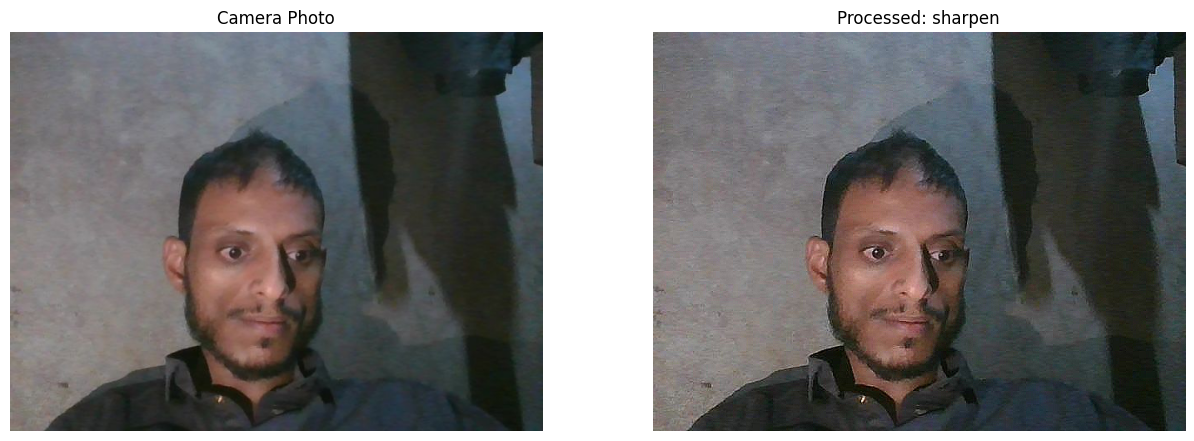

In [28]:
CAPTURE_CAMERA_PHOTO = False
PHOTO_WIDTH = 640
PHOTO_JPEG_QUALITY = 0.80
PHOTO_PROCESSING_MODE = 'sharpen'

if CAPTURE_CAMERA_PHOTO:
    if not CAMERA_JAVASCRIPT_READY:
        raise RuntimeError('شغّل الدفتر داخل Google Colab لاستخدام الكاميرا.')

    photo_data_url = capture_photo_from_browser(
        width=PHOTO_WIDTH, quality=PHOTO_JPEG_QUALITY
    )
    captured_photo = data_url_to_bgr(photo_data_url)
    timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    original_photo_path = (
        IMAGE_INPUT_DIR / f'camera_photo_{timestamp}.jpg'
    )
    processed_photo_path = (
        CAMERA_IMAGE_OUTPUT_DIR
        / f'camera_photo_{timestamp}_{PHOTO_PROCESSING_MODE}.jpg'
    )

    processed_photo = process_camera_frame(
        captured_photo, mode=PHOTO_PROCESSING_MODE
    )
    cv2.imwrite(str(original_photo_path), captured_photo)
    cv2.imwrite(str(processed_photo_path), processed_photo)

    print('Original photo saved:', original_photo_path)
    print('Processed photo saved:', processed_photo_path)
    show_comparison({
        'Camera Photo': captured_photo,
        f'Processed: {PHOTO_PROCESSING_MODE}': processed_photo
    })
else:
    print('التقاط الصورة معطل. غيّر CAPTURE_CAMERA_PHOTO إلى True عند الحاجة.')

## 7. تسجيل فيديو قصير من الكاميرا

التسجيل مضبوط على دقة منخفضة وBitrate صغير ليتناسب مع سرعة الرفع. غيّر `RECORD_CAMERA_VIDEO` إلى `True` ثم نفّذ الخلية. سيُحفظ WebM الأصلي، وتحاول الخلية إنشاء نسخة MP4 باستخدام FFmpeg.

In [25]:
def convert_webm_to_mp4(input_path, output_path):
    ffmpeg_path = shutil.which('ffmpeg')
    if ffmpeg_path is None:
        return False, 'FFmpeg غير متاح؛ بقي التسجيل بصيغة WebM.'

    command = [
        ffmpeg_path, '-y',
        '-i', str(input_path),
        '-c:v', 'libx264',
        '-preset', 'fast',
        '-crf', '25',
        '-pix_fmt', 'yuv420p',
        '-c:a', 'aac',
        '-b:a', '96k',
        '-movflags', '+faststart',
        str(output_path)
    ]
    try:
        subprocess.run(
            command, check=True,
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE
        )
        return True, 'تم إنشاء نسخة MP4 بنجاح.'
    except subprocess.CalledProcessError as error:
        details = error.stderr.decode('utf-8', errors='ignore')[-500:]
        print('FFmpeg warning:', details)
        return False, 'تعذر التحويل؛ ملف WebM ما زال محفوظًا.'


RECORD_CAMERA_VIDEO = False
RECORDING_SECONDS = 5
RECORDING_WIDTH = 480
RECORDING_HEIGHT = 360
RECORDING_BITRATE = 250_000

if RECORD_CAMERA_VIDEO:
    if not CAMERA_JAVASCRIPT_READY:
        raise RuntimeError('شغّل الدفتر داخل Google Colab لاستخدام الكاميرا.')

    recording_result = record_video_from_browser(
        seconds=RECORDING_SECONDS,
        width=RECORDING_WIDTH,
        height=RECORDING_HEIGHT,
        bitrate=RECORDING_BITRATE
    )
    raw_payload = recording_result['base64Payload']

    # بعض رسائل Colab تضيف محارف تحكم بين أجزاء النص.
    # نحول URL-safe Base64 إن وُجد، ثم نحتفظ بمحارف Base64 فقط.
    raw_payload = raw_payload.replace('-', '+').replace('_', '/')
    allowed_characters = set(
        'ABCDEFGHIJKLMNOPQRSTUVWXYZ'
        'abcdefghijklmnopqrstuvwxyz'
        '0123456789+/='
    )
    recording_payload = ''.join(
        character for character in raw_payload
        if character in allowed_characters
    )

    # يجب أن يظهر padding في النهاية فقط.
    recording_payload = recording_payload.rstrip('=')
    remainder = len(recording_payload) % 4
    if remainder == 1:
        # محرف زائد ناتج عن النقل؛ حذفه يعيد بنية Base64 الصحيحة.
        recording_payload = recording_payload[:-1]
        remainder = len(recording_payload) % 4
    if remainder:
        recording_payload += '=' * (4 - remainder)

    recording_bytes = b64decode(
        recording_payload,
        validate=False
    )
    if len(recording_bytes) < 4:
        raise RuntimeError('ملف الفيديو الناتج فارغ أو غير مكتمل.')
    if not recording_bytes.startswith(b'\x1aE\xdf\xa3'):
        print(
            'تحذير: لم تظهر ترويسة WebM القياسية، '
            'لكن سيتم حفظ الملف ومحاولة تحويله.'
        )
    timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    webm_path = VIDEO_INPUT_DIR / f'camera_recording_{timestamp}.webm'
    mp4_path = VIDEO_INPUT_DIR / f'camera_recording_{timestamp}.mp4'
    webm_path.write_bytes(recording_bytes)

    converted, message = convert_webm_to_mp4(webm_path, mp4_path)
    print(message)
    print(
        'Recorded size:',
        f"{recording_result['sizeBytes'] / 1024:.1f} KB"
    )
    print('Audio captured:', recording_result['hasAudio'])
    print('WebM saved:', webm_path)
    if converted:
        print('MP4 saved:', mp4_path)
        print('يمكن الآن فتح هذا الفيديو في الدفتر 06.')
else:
    print('تسجيل الفيديو معطل. غيّر RECORD_CAMERA_VIDEO إلى True عند الحاجة.')

تحذير: لم تظهر ترويسة WebM القياسية، لكن سيتم حفظ الملف ومحاولة تحويله.
FFmpeg warning: c    57.  3.100 / 57.  3.100
[matroska,webm @ 0x5576ce389340] Format matroska,webm detected only with low score of 1, misdetection possible!
[matroska,webm @ 0x5576ce389340] EBML header parsing failed
[in#0 @ 0x5576ce389240] Error opening input: Invalid data found when processing input
Error opening input file /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Videos/Input/camera_recording_20260917_231849.webm.
Error opening input files: Invalid data found when processing input

تعذر التحويل؛ ملف WebM ما زال محفوظًا.
Recorded size: 73.9 KB
Audio captured: False
WebM saved: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Videos/Input/camera_recording_20260917_231849.webm


## 8. معالجة لقطات متتابعة من الكاميرا وحفظ فيديو معالج

في Colab تُلتقط مجموعة قصيرة من الإطارات داخل استدعاء JavaScript واحد، ثم يعالجها OpenCV ويحفظها كفيديو. هذا هو البديل المستقر للمعالجة الحية في Colab؛ أما تطبيق Android فسينفذ المعالجة الحقيقية إطارًا بإطار عبر CameraX دون إنترنت.

غيّر `RUN_LIVE_CAMERA` إلى `True` واختر `LIVE_PROCESSING_MODE`. يمكنك الانتظار حتى انتهاء الالتقاط أو الضغط على **Stop Camera**.

اسمح باستخدام الكاميرا وانتظر اكتمال الالتقاط...
Frames captured: 16
Capture/transfer time: 12.37 seconds
OpenCV processing time: 0.02 seconds
OpenCV processing speed: 879.18 FPS
Browser-compatible conversion: True
Processed video saved: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Videos/07_Live_Camera_Processing/live_20260917_231949_canny.mp4
Last processed frame saved: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/07_Live_Camera_Processing/live_20260917_231949_canny.jpg


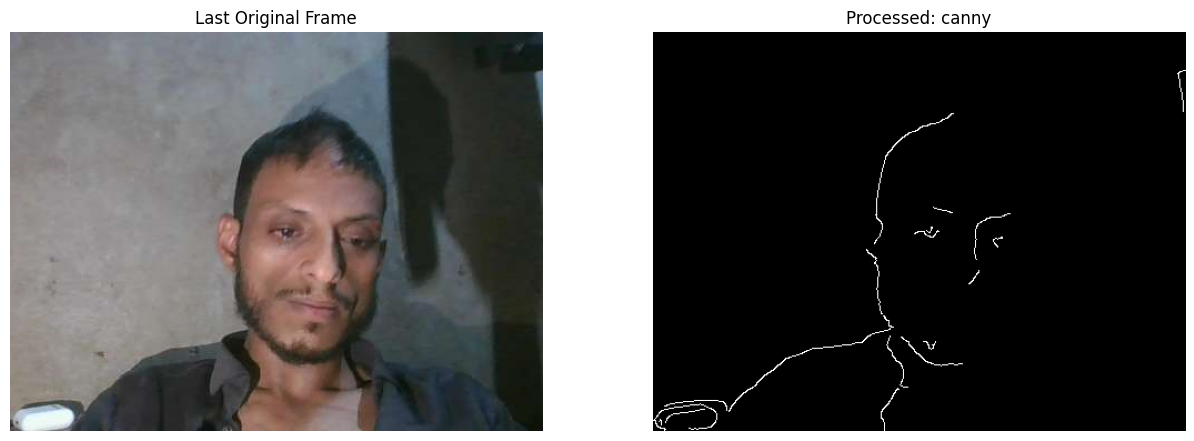

In [27]:
def save_frames_as_mp4(frames, output_path, fps):
    if not frames:
        raise ValueError('لا توجد إطارات لحفظها.')

    first = even_dimensions(frames[0])
    height, width = first.shape[:2]
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    writer = cv2.VideoWriter(
        str(output_path), fourcc, float(fps), (width, height)
    )
    if not writer.isOpened():
        raise RuntimeError('تعذر إنشاء فيديو الكاميرا المعالج.')

    for frame in frames:
        frame = even_dimensions(frame)
        if frame.shape[:2] != (height, width):
            frame = cv2.resize(frame, (width, height))
        writer.write(frame)
    writer.release()


def convert_silent_mp4(input_path, output_path):
    ffmpeg_path = shutil.which('ffmpeg')
    if ffmpeg_path is None:
        shutil.copy2(input_path, output_path)
        return False

    command = [
        ffmpeg_path, '-y', '-i', str(input_path),
        '-c:v', 'libx264', '-preset', 'fast', '-crf', '23',
        '-pix_fmt', 'yuv420p', '-movflags', '+faststart',
        str(output_path)
    ]
    try:
        subprocess.run(
            command, check=True,
            stdout=subprocess.PIPE, stderr=subprocess.PIPE
        )
        return True
    except subprocess.CalledProcessError:
        shutil.copy2(input_path, output_path)
        return False


RUN_LIVE_CAMERA = False
LIVE_PROCESSING_MODE = 'canny'
LIVE_SECONDS = 8
LIVE_CAMERA_WIDTH = 480
LIVE_CAMERA_HEIGHT = 360
LIVE_JPEG_QUALITY = 0.60
LIVE_CAPTURE_FPS = 2
LIVE_MAX_FRAMES = 40

if RUN_LIVE_CAMERA:
    if not CAMERA_JAVASCRIPT_READY:
        raise RuntimeError('شغّل الدفتر داخل Google Colab لاستخدام الكاميرا.')
    if LIVE_PROCESSING_MODE not in CAMERA_PROCESSING_MODES:
        raise ValueError('وضع المعالجة غير مدعوم.')

    requested_frames = min(
        int(LIVE_MAX_FRAMES),
        max(1, int(LIVE_SECONDS * LIVE_CAPTURE_FPS))
    )
    interval_ms = max(100, int(1000 / LIVE_CAPTURE_FPS))

    print('اسمح باستخدام الكاميرا وانتظر اكتمال الالتقاط...')
    capture_start = time.perf_counter()
    burst_result = capture_burst_from_browser(
        frame_count=requested_frames,
        interval_ms=interval_ms,
        width=LIVE_CAMERA_WIDTH,
        height=LIVE_CAMERA_HEIGHT,
        quality=LIVE_JPEG_QUALITY
    )
    capture_elapsed = time.perf_counter() - capture_start

    original_frames = [
        even_dimensions(
            data_url_to_bgr(frame_data),
            LIVE_CAMERA_WIDTH
        )
        for frame_data in burst_result.get('frames', [])
    ]

    processing_start = time.perf_counter()
    processed_frames = [
        process_camera_frame(
            frame,
            mode=LIVE_PROCESSING_MODE,
            low_threshold=100,
            high_threshold=200,
            threshold_value=127
        )
        for frame in original_frames
    ]
    processing_elapsed = time.perf_counter() - processing_start

    if processed_frames:
        timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
        temporary_video_path = (
            CAMERA_VIDEO_OUTPUT_DIR
            / f'live_{timestamp}_{LIVE_PROCESSING_MODE}_opencv.mp4'
        )
        final_video_path = (
            CAMERA_VIDEO_OUTPUT_DIR
            / f'live_{timestamp}_{LIVE_PROCESSING_MODE}.mp4'
        )
        snapshot_path = (
            CAMERA_IMAGE_OUTPUT_DIR
            / f'live_{timestamp}_{LIVE_PROCESSING_MODE}.jpg'
        )

        output_fps = max(1.0, float(LIVE_CAPTURE_FPS))
        save_frames_as_mp4(
            processed_frames, temporary_video_path, output_fps
        )
        converted = convert_silent_mp4(
            temporary_video_path, final_video_path
        )
        cv2.imwrite(str(snapshot_path), processed_frames[-1])

        processing_fps = (
            len(processed_frames) / processing_elapsed
            if processing_elapsed > 0 else 0.0
        )
        print('Frames captured:', len(processed_frames))
        print(f'Capture/transfer time: {capture_elapsed:.2f} seconds')
        print(f'OpenCV processing time: {processing_elapsed:.2f} seconds')
        print(f'OpenCV processing speed: {processing_fps:.2f} FPS')
        print('Browser-compatible conversion:', converted)
        print('Processed video saved:', final_video_path)
        print('Last processed frame saved:', snapshot_path)

        show_comparison({
            'Last Original Frame': original_frames[-1],
            f'Processed: {LIVE_PROCESSING_MODE}': processed_frames[-1]
        })
    else:
        print('لم تُلتقط إطارات. تحقق من إذن الكاميرا ثم أعد المحاولة.')
else:
    print('التقاط الإطارات معطل. غيّر RUN_LIVE_CAMERA إلى True عند الحاجة.')

## 9. الإعدادات المقترحة للإنترنت البطيء

| الإعداد | القيمة المقترحة |
|---|---:|
| تسجيل الكاميرا | 5 ثوانٍ |
| دقة التسجيل | 480 × 360 |
| Video Bitrate | 250 Kbps |
| مدة المعالجة المباشرة | 5–8 ثوانٍ |
| عرض إطار المعالجة | 480 بكسل |
| جودة JPEG | 0.60 |
| الحد الأعلى للإطارات | 100 |

إذا لاحظت تأخرًا كبيرًا، استخدم عرضًا `320` وجودة `0.45`. هذه القيود خاصة بتجربة Colab ولا تنطبق على تطبيق Android المحلي.

## 10. ما الذي يُحفظ وأين؟

| النتيجة | المجلد |
|---|---|
| الصورة الأصلية الملتقطة | `02_Data/Images/Input` |
| الفيديو الأصلي المسجل | `02_Data/Videos/Input` |
| الصور المعالجة من الكاميرا | `04_Outputs/Images/07_Live_Camera_Processing` |
| فيديو المعالجة المباشرة | `04_Outputs/Videos/07_Live_Camera_Processing` |

بهذا يمكن استخدام الصورة الملتقطة في الدفاتر 01–05، واستخدام الفيديو المسجل في الدفتر 06 دون رفع الملف مرة أخرى.

## 11. الربط بتطبيق Android

| تجربة Colab | تطبيق Android النهائي |
|---|---|
| `getUserMedia` | CameraX Preview |
| نقل JPEG إلى Python | CameraX ImageAnalysis محليًا |
| `process_camera_frame` | دالة OpenCV تستقبل `Mat` |
| MediaRecorder في المتصفح | CameraX VideoCapture |
| حفظ النتائج في Drive | حفظ محلي في MediaStore |
| سرعة محدودة بالإنترنت | معالجة محلية دون إنترنت |

في Android سنستخدم ثلاث حالات منفصلة:

1. **Preview:** عرض الكاميرا.
2. **ImageAnalysis:** أخذ الإطارات وتطبيق OpenCV أو YOLO.
3. **ImageCapture/VideoCapture:** التقاط الصور وتسجيل الفيديو.

## 12. مشكلات متوقعة وحلولها

- **لم يظهر طلب إذن الكاميرا:** تأكد أن إذن الكاميرا مسموح للموقع من إعدادات المتصفح.
- **الكاميرا مستخدمة:** أغلق Zoom أو أي برنامج يستخدم الكاميرا.
- **المعالجة بطيئة:** استخدم عرض `320` أو وضع Grayscale/Canny بدل Bilateral.
- **انقطع التنفيذ:** التسجيل الأصلي الذي اكتمل يبقى محفوظًا في Drive.
- **دفتر Colab أصبح كبيرًا:** بعد التأكد من حفظ النتائج استخدم `Edit → Clear all outputs`.
- **تكررت محاولة الكاميرا:** أعد تشغيل خلية JavaScript ثم خلية الوضع المطلوب.

## 13. أسئلة للمناقشة والتقرير

1. لماذا لا يعمل `cv2.VideoCapture(0)` مباشرة في Colab؟
2. ما سبب انخفاض FPS في المعالجة الحية داخل Colab؟
3. كيف تؤثر جودة JPEG وحجم الإطار على السرعة؟
4. لماذا لا يحتوي فيديو المعالجة الحية على صوت؟
5. ما الفرق بين Preview وImageAnalysis وVideoCapture في CameraX؟
6. أي الفلاتر كان مناسبًا أكثر للزمن الحقيقي؟
7. لماذا سيكون تطبيق Android أسرع من تجربة Colab؟

**الخطوة التالية:** الدفتر `08_Face_Eye_Detection.ipynb` لتطبيق LAB 10 على الصور والفيديو والكاميرا.